# Import the libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm

# Data

## Import

In [3]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"

df = pd.read_csv(url)

display(df.head()) #shows the first 5 raws of the dataframe

print("Numero di righe:", len(df)) #prints the number of rows in the dataframe

print("Nomi delle colonne:", df.columns.tolist()) #prints the names of the columns in the dataframe

,observation_date,SP500
0,2016-10-24,2151.33
1,2016-10-25,2143.16
2,2016-10-26,2139.43
3,2016-10-27,2133.04
4,2016-10-28,2126.41


Numero di righe: 2608
Nomi delle colonne: ['observation_date', 'SP500']


## Cleaning the data

The market is not always open, for example it closes during weekends and holidays. The $S
\&P500$ index is marked in the dataset as a NaN value.

In [4]:
print("\nWe have ", len( df[df['observation_date'].isna()]), "NaN values in the observation_date column")
print("\nWe have ", len( df[df['SP500'].isna()]), "NaN values in the SP500 column") #prints the number of NaN values in the SP500 column


We have  0 NaN values in the observation_date column

We have  96 NaN values in the SP500 column


In [5]:
print(df.dtypes)

# Convert the observation_date column to datetime format
df["observation_date"] = pd.to_datetime(df["observation_date"]) 
print("\nObserve the type of the column is not str anymore:")
print(df.dtypes) 

# Remove rows containing missing values
prices = df.dropna()
print("\nNew shape after removing NaN values:", prices.shape)

# Sort observations chronologically
prices = prices.sort_values("observation_date").reset_index(drop=True)

# Rename the date column
prices = prices.rename(columns={"observation_date": "Date"})
print("Now the name of the columns is", prices.columns.to_list())


print("Original observations:", len(df))
print("Valid observations:", len(prices))

display(prices.head())
display(prices.tail())


observation_date        str
SP500               float64
dtype: object

Observe the type of the column is not str anymore:
observation_date    datetime64[us]
SP500                      float64
dtype: object

New shape after removing NaN values: (2512, 2)
Now the name of the columns is ['Date', 'SP500']
Original observations: 2608
Valid observations: 2512


,Date,SP500
0,2016-10-24,2151.33
1,2016-10-25,2143.16
2,2016-10-26,2139.43
3,2016-10-27,2133.04
4,2016-10-28,2126.41


,Date,SP500
2507,2026-10-15,7744.06
2508,2026-10-16,7659.44
2509,2026-10-19,7690.73
2510,2026-10-20,7712.57
2511,2026-10-21,7757.17


## Plotting the data

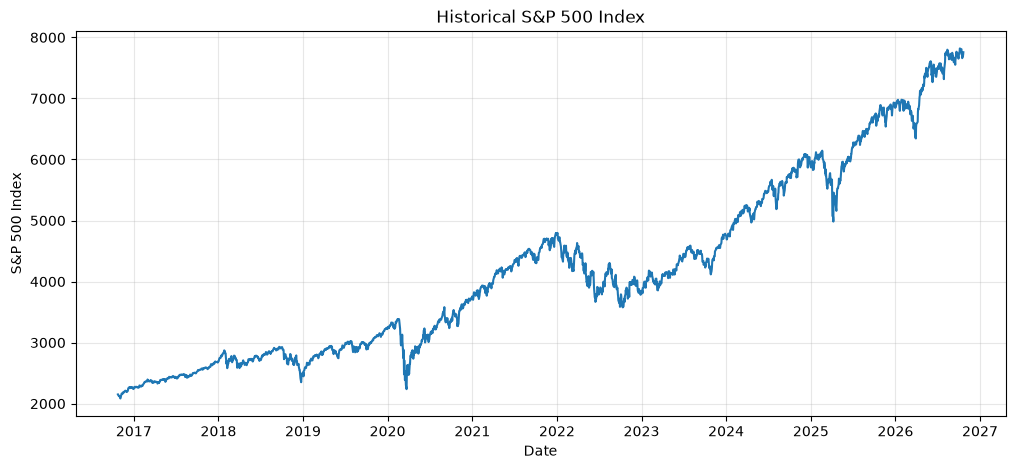

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(prices["Date"], prices["SP500"])

plt.xlabel("Date")
plt.ylabel("S&P 500 Index")
plt.title("Historical S&P 500 Index")

plt.grid(alpha=0.3)
plt.show()

# Logarithmic returns distribution analisys

## Compute the logarithmic returns

In this work, we are interested in the distribution of the logarithmic returns $r_t$, defined as

$$
r_t \equiv \ln\left(\frac{P_t}{P_{t-1}}\right).
$$


In [7]:
#create a new dataframe for return analisys

returns_df = prices.copy() 
returns_df.columns.to_list()
returns_df["Returns"] = np.log(returns_df["SP500"]/returns_df["SP500"].shift(1))
returns_df = returns_df.dropna()

print(returns_df.head())
print(returns_df.tail())

        Date    SP500   Returns
1 2016-10-25  2143.16 -0.003805
2 2016-10-26  2139.43 -0.001742
3 2016-10-27  2133.04 -0.002991
4 2016-10-28  2126.41 -0.003113
5 2016-10-31  2126.15 -0.000122
           Date    SP500   Returns
2507 2026-10-15  7744.06  0.003249
2508 2026-10-16  7659.44 -0.010987
2509 2026-10-19  7690.73  0.004077
2510 2026-10-20  7712.57  0.002836
2511 2026-10-21  7757.17  0.005766


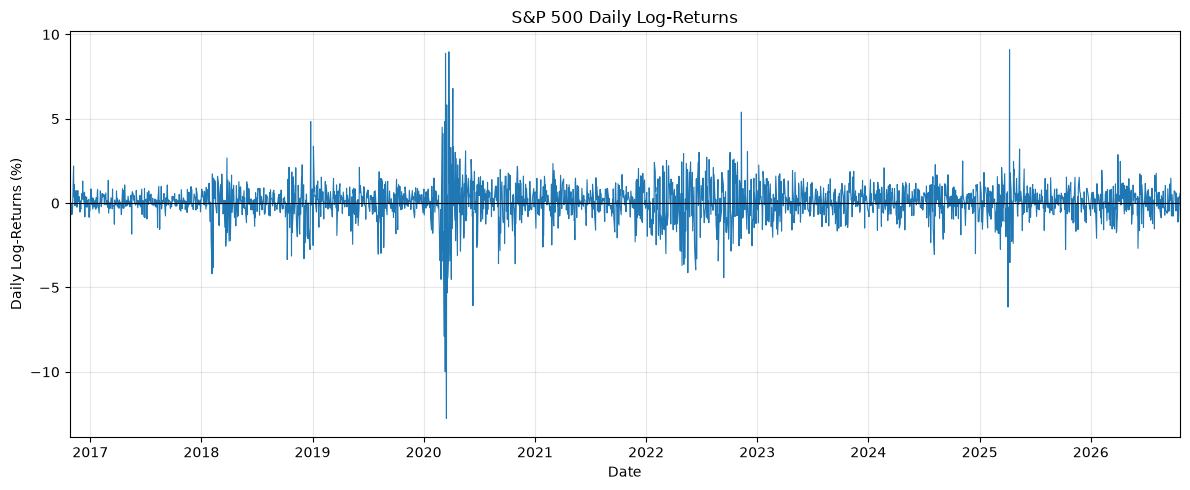

count    2511.000000
mean        0.000511
std         0.011418
min        -0.127652
25%        -0.003766
50%         0.000769
75%         0.005866
max         0.090895
Name: Returns, dtype: float64

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(returns_df["Date"], 100 * returns_df["Returns"], linewidth=0.8)

ax.axhline(0, color="black", linewidth=0.8)

# Make the plot start and end exactly at the first and last observations
ax.set_xlim(returns_df["Date"].min(), returns_df["Date"].max())

ax.set_xlabel("Date")
ax.set_ylabel("Daily Log-Returns (%)")
ax.set_title("S&P 500 Daily Log-Returns")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

returns_df["Returns"].describe()

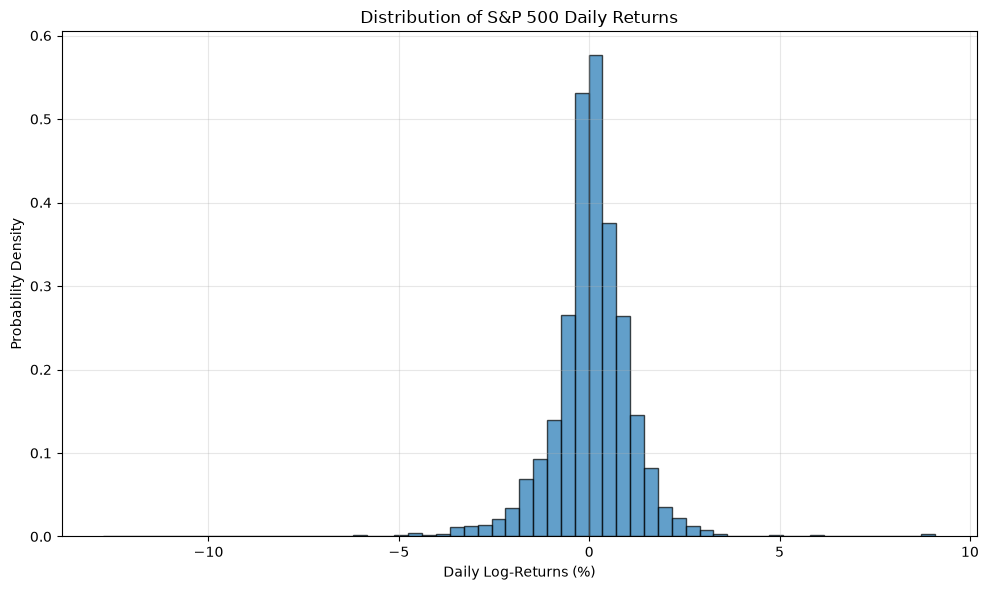

In [9]:
# Daily log-returns expressed as percentages
r = 100 * returns_df["Returns"]

# Histogram
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(r, bins=60, density=True, edgecolor="black", alpha=0.7)

ax.set_xlabel("Daily Log-Returns (%)")
ax.set_ylabel("Probability Density")
ax.set_title("Distribution of S&P 500 Daily Returns")

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Statistical analisys 

### Warmp up: the Gaussian iid model 

In this section we begin the statistical analisys the $r_t$ distribution. In particular, we will consider a measurement of the logarithmic return at a time $t$, $r_t$, as an istance of a random variable $R_t$. Our first goal is to investigate whether the data are compatible with the hypothesis

$$

H_0: \quad R_t \overset{\text{iid}}{\sim} \mathcal{N}(\mu, \sigma^2) 

$$

describes the data. This is admittedly an over-simplified model, since it assumes that returns are independent and identically distributed, with a constant mean and variance over time. 


Nevertheless, the Gussian iid model provides a useful starting point and a benchmark against which more sophisticated models can be compared. 


We begin by plotting a normalized histogram of the observed returns to obtain an empirical estimate of their pdf. 

#### Naive superposition

In [10]:
mu_hat = r.mean()
sigma_hat = r.std() 
print("The estimated mean is", mu_hat)
print("The estimated standard dev", sigma_hat)

The estimated mean is 0.051076516185738566
The estimated standard dev 1.1417842892073282


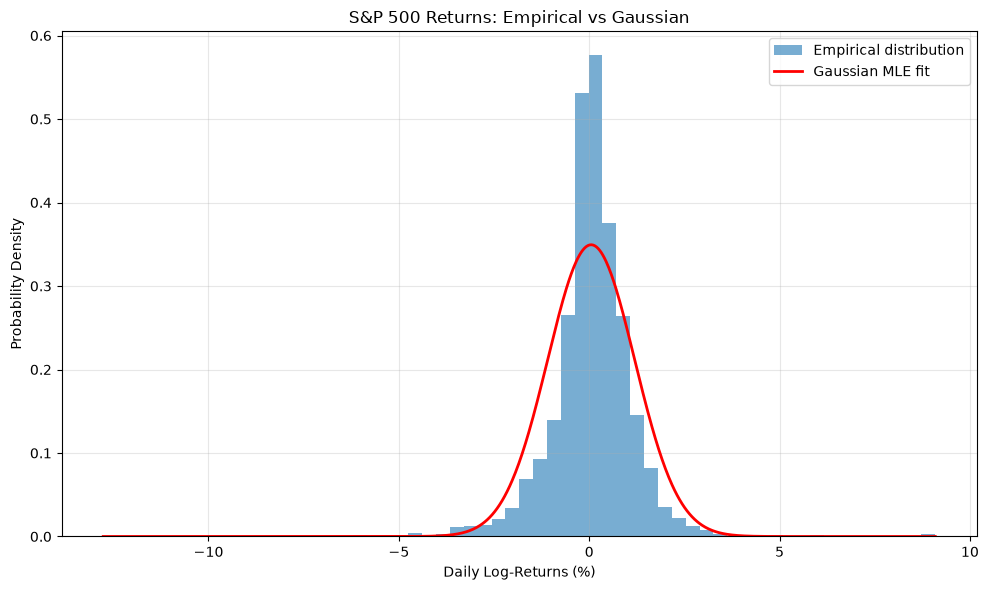

In [11]:
# Generate points for the theoretical Gaussian curve
x = np.linspace(r.min(), r.max(), 1000)

# Evaluate Gaussian probability density
gaussian_pdf = norm.pdf(x, loc=mu_hat, scale=sigma_hat)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

# Empirical distribution
counts, binhedge, patches =  ax.hist(
    r,
    bins=60,
    density=True,
    alpha=0.6,
    label="Empirical distribution"
)


# Gaussian model
ax.plot(
    x,
    gaussian_pdf,
    color="red",
    linewidth=2,
    label="Gaussian MLE fit"
)

ax.set_xlabel("Daily Log-Returns (%)")
ax.set_ylabel("Probability Density")
ax.set_title("S&P 500 Returns: Empirical vs Gaussian")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Goodness-of-fit test with Pearson Chi2

What we want to do here is to understand wether the observed data is compatible with the hypotesys  

$$

H_0: R_t \overset{\text{iid}}{\sim} \mathcal{N}(\mu,\sigma^2).

$$



The first we have to in order to set a Pearson-$\chi^2$ test is to choose the binning. We want the expected frequency in each bin to be sufficiently large for to assume that the number of observed data in each bin follows a Poisson distribution. Therefore, we divide the interval $\{-\infty,\infty\}$ in $B = 20$ bins such that

Therefore, we divide the interval $(-\infty,\infty)$ in $B = 20$ bins such that

$$
P(r_i \in I_a) = p, \qquad a = 1,\dots,B, \tag{1}
$$
with $p= 1/B = 0.05$, and  $I_a$ denoting the intervals of the binning.

Such intervals are determined as follows. First of all we introduce the notation for the edges of the intervals that define the binning: 

$$

I_a = (b_a, b_{n+1}).

$$

Now we notice that Eq.(1) can be rewritten as 

$$

F_{H_0}(b_i) = \frac{(i-1)}{B},

$$

with $F_{H_0}$ the cumulative under the null hypothesis $H_0$. 

The intervals are thus found as 

$$

b_i = F_{H_0}^{-1}\biggl(\frac{i-1}{B}\biggr).

$$




In [12]:
# Daily log-returns in percentage
r = r.to_numpy()

In [13]:
B = 20 
p = np.arange(B+1)/B

b = norm.ppf(p, mu_hat, sigma_hat  ) # inverse cumulative of a gaussian

print("Number of edges:",len(b))
print("First few edges:",b[0:5])


Number of edges: 21
First few edges: [       -inf -1.82699151 -1.41217893 -1.13230684 -0.90987339]


In [14]:
# rebinning:
O, _ = np.histogram(r, bins=b)

print("Observed counts:", O)
print("Total observations:", O.sum())

N = len(r)

E = N / B

print("\nExpected counts per bin:", E)


X2_obs = np.sum((O-E)**2/E)

print("\nObserved Pearson Chi2:", X2_obs)



Observed counts: [105  72  62  61  97 107 108 162 207 234 234 175 163 147 140 109 117  77
  65  69]
Total observations: 2511

Expected counts per bin: 125.55

Observed Pearson Chi2: 466.21226602947036


Normally, in order to interpret this results, one might be tempted to rely on the asymptotic chi-square distribution of the Pearson's test statistic and use it to compute the probability of obtaining a value greater that the one observed. However, we estimated the parameters $\hat \mu$ and $\hat \sigma$ using the observed data, meaning that our bin boundaries also depend on the observed sample. 

In order to understand the consequences of this fact, consider the simple example in which we have only two observations $r_1$ and $r_2$. Now we build the bin using the average 

$$

\hat \mu = \frac{1}{2}(r_1 +r_2).

$$

we can assume WLG that $r_1 < \hat \mu < r_2$, denoting with $O_i$ the observed number of  observations in the bin $i$, we then have

$$

(O_1,O_2) = (1,1).

$$

However, using the true unknown average, we might have found 

$$

(O_1,O_2) = (2,0),(1,1),(0,2).

$$

This means that estimating the parameters from the data we have modified the possible fluctuations of the observed number of observations in each bin. As a consequence, the asymptotic distribution of the Pearson's chi-square is no longer necessarilty the one predicted by the asymptotic theorem. 

For this reason, we perform a parametric bootstrap in order to numerically build the distribution of the test statitics. 
In the following, we explain how this works. 

We begin by generating a sample of $N = 2512 $ data under the hypothesis $H_0$:

$$

R_t^{*} \sim \mathcal{N}(\hat \mu, \hat \sigma),

$$

and estimate again the paramters

$$

\hat \mu^{*} = \frac1N \sum_{t^1}^N r_t^{*}, \quad (\hat \sigma^{*})^2 = \frac{1}{N-1}\sum_{t= 1}^{N} (r_t- \hat \mu^*)^2. 

$$

Now we compute again the Pearson chi-square 

$$

\chi^{2\, *}_{pearson} = \sum_{a=1}^{N}\frac{(O_a^{*} - N/B)^2}{N/B}.

$$


We now generate $n = 5000$ samples under the null hypothesis, then we re-estimate the parameters and compute the  pearson chi-square for each of the $n$ samples.  

In [15]:
n = 5000
rstar = []
l = []
i = 0 
while i < n:
    rnew = np.random.normal(mu_hat,sigma_hat,size=len(r))
    rstar.append(rnew)
    l.append([rnew.mean(),rnew.std()])
    i+=1

l = np.array(l)
rstar = np.array(rstar)

bstar  = norm.ppf(p,l[:,0,None], l[:,1,None])

Ostar = []
i = 0
while i < n:
    Onew,_ = np.histogram(rstar[i], bins=bstar[i,:])
    Ostar.append(Onew)
    i+=1

Ostar = np.array(Ostar)
print(Ostar.shape)


X2star = np.sum((Ostar- E)**2/E,axis=1)

X2star.shape


(5000, 20)


(5000,)

Now we plot the histogram of the n estractions of the Pearson chi-square

<function matplotlib.pyplot.show(close=None, block=None)>

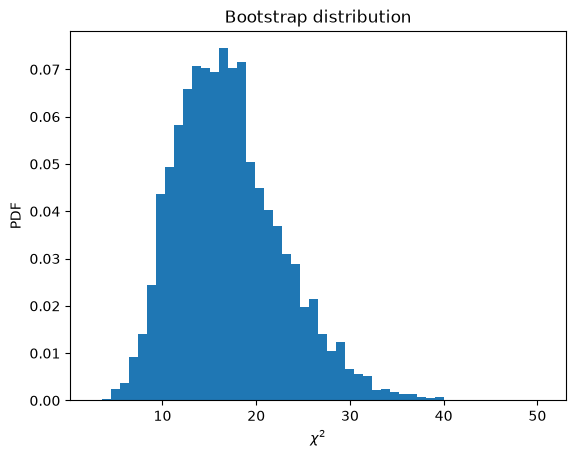

In [16]:
plt.hist(X2star, bins = 50, density=True)

plt.xlabel(r'$\chi^2$')
plt.ylabel('PDF')
plt.title('Bootstrap distribution')

plt.show

In [18]:
K = np.sum(X2star >= X2_obs)
pvalue = (K+1)/(n+1)
print("The obtained p-value is", pvalue) 

The obtained p-value is 0.0001999600079984003


Such a small p-value leads us to reject the null hypothesis (H_0) at any conventional significance level, in agreement with our expectations.

However, such result does not tell us exactly why the model fails. Indeed, the hypothesis $H_0$ assumes  both that the returns follow a Gaussian distribution and that they are independent and identically distributed, with a constant mean and variance over time. 

The empirical histogram suggests that the distribution of returns is more sharply peaked and has heavier tails than the fitted gaussian.These features may arise from a non gaussian distribution or from fluctuations in volatility over time. 

By volatility we refer to a quantity that measures the fluctuations of the returns. In statistical terms, this is basically a standard deviation.  In the case of the Gaussian iid model, the volatility was just the standard deviation. 



### Gaussian model with Time-Varying volatility

$\textbf{Introduction}$

In this section we study a gaussian model with Time-varying Volatility, we will refer to this as the gaussian TVT model. The null hypothesis is now

$$

H_0: \quad R_t = \mu + \Sigma_t Z_t, \quad Z_t \sim \mathcal{N}(0,1),

$$

where $\Sigma_t>0$ is a function of the information available the time $t-1$, denoted by $\mathcal{F}_{t-1}$. We further assume that  $Z_t$ is independent of $\mathcal F_{t-1}$. Therefore, we can write our new null hypothesis in the more compact form 

$$
H_0: \quad R_t\mid\mathcal F_{t-1}
\sim\mathcal N(\mu,\Sigma_t^2).
$$


We have

$$
\mathbb E[R_t\mid\mathcal F_{t-1}]=\mu,
\qquad
\operatorname{Var}(R_t\mid\mathcal F_{t-1})=\Sigma_t^2.


$$

Notice that, differently from the gaussian iid model, the (conditional) variance $\operatorname{Var}(R_t\mid\mathcal F_{t-1}) $ now depends on previous observations.  

However, we have not yet specified the dynamics of $\Sigma_t^2$. Before introducing a particular model for its evolution, we investigate whether the observed returns exhibit temporal dependence. We notice that, in our model, the correlation between returns at different times vanishes:

$$

\operatorname{Cov}(R_{t-k}, R_t) = 0 \qquad k\geq 1,

$$

This means that past returns do not provide information information about returns throught their linear correlation. However, the square of the returns at different times may exhibit in general non-zero correlation

$$

\operatorname{Cov}(R_t^2,R_{t-k}^2)= \operatorname{Cov}(\Sigma_t^2,R_{t-k}^2),\qquad k\geq 1. 

$$

Notice that the above quantity is zero in the gaussian iid model ($\Sigma_t = \sigma$). 

The possible positive correlation between the amplitude of the fluctuations of the returns is closely related to a phenomenon called $\textit{volatility clustering}$, commonly observerd in financial time series.  It refers to the tendency of large fluctuations in returns to occur close in time, regardless of their sign. Similarly, periods characterized by relatively small fluctuations tend to persist.  



$\textbf{Weakly stationary processes}$

Before proceeding with the analysis of temporal correlations, we restrict our attention to volatility dynamics for which both $R_t$ and $R_t$ are weakly stationary processes. 

A stochastic process $X_t$ is said to be weakly stationary if 

$$

\mathbb{E}[X_t] =  x, \quad \operatorname{Cov}(X_t,X_{t+k} ) =  \gamma_k, \forall \kappa \geq 0 

$$

In our model, we have already shown that 

$$

\mathbb E[R_t]=\mu,\qquad
\operatorname{Cov}(R_t,R_{t-k})=0,\quad k\geq1, 

$$

while for $k = 0 $ we find

$$

\operatorname{Cov}(R_t,R_t)= \operatorname{Var}(R_t) = \mathbb{E}[\Sigma_t^2]. 

$$

Thus in our model the stochastic process $R_t$  is weakly stationary if $\mathbb{E}[\Sigma_t^2] = \Sigma^2 < \infty$. For $R^2_t$ we have instead

$$
\begin{aligned}
    \mathbb{E}[R_t^2] &= \mu^2 + \mathbb{E} [\Sigma_t^2] = \mu^2 + \Sigma^2  , \\
    \operatorname{Cov}(R_t^2,R_{t-k}^2) &= \operatorname{Cov}(\Sigma_t^2,R_{t-k}^2),
\end{aligned}
$$

with $\kappa \geq 1 $. 

Under the weak stationary assumption, we can defined the autocorrelation function (ACF) of a stochastic process $X_t$ as 

$$

\rho_X(\kappa)= \frac{\gamma_\kappa }{\gamma_0}. 


$$

For our Gaussian TVT model, the autocorrelation function of the returns satisfies

$$
\rho_R(\kappa)=0,\qquad \kappa\geq1,
$$

while the autocorrelation function of the squared returns is

$$
\rho_{R^2}(\kappa)=
\frac{\operatorname{Cov}(\Sigma_t^2,R_{t-\kappa}^2)}
{\operatorname{Var}(R_t^2)},
\qquad \kappa\geq1.
$$

As already stated, even though the returns are uncorrelated, their squares may exhibit nonzero autocorrelation, and positive autocorrelations in squared returns provide evidence of volatility clustering.

We now investigate whether this behavior is present in the S&P 500 daily returns

Given a sample of $N$ observations $x_1,\ldots,x_N$, we estimate the autocorrelation at lag $\kappa$ using

$$
\hat{\rho}_X(\kappa)=
\frac{
\sum_{t=\kappa+1}^{N}(x_t-\bar{x})(x_{t-\kappa}-\bar{x})
}{
\sum_{t=1}^{N}(x_t-\bar{x})^2
},
$$

where $\bar{x}$ is the sample mean. We apply this estimator to both the observed returns $r_t$ and the squared returns $r_t^2$.



  asa